PREPROCESSING & EDA

Loading data...
Missing values handled: 0 interpolated.

Menampilkan 5 baris pertama data setelah dibersihkan:


,pm2_5,suhu_C,kelembapan_%,curah_hujan_mm,angin_kmh
waktu,,,,,
2023-01-01 00:00:00,20.8,23.9,92,0.0,16.3
2023-01-01 01:00:00,19.3,23.9,92,0.0,16.9
2023-01-01 02:00:00,17.5,23.6,92,0.0,18.4
2023-01-01 03:00:00,15.6,23.7,91,0.0,20.0
2023-01-01 04:00:00,14.1,23.5,91,0.1,20.7


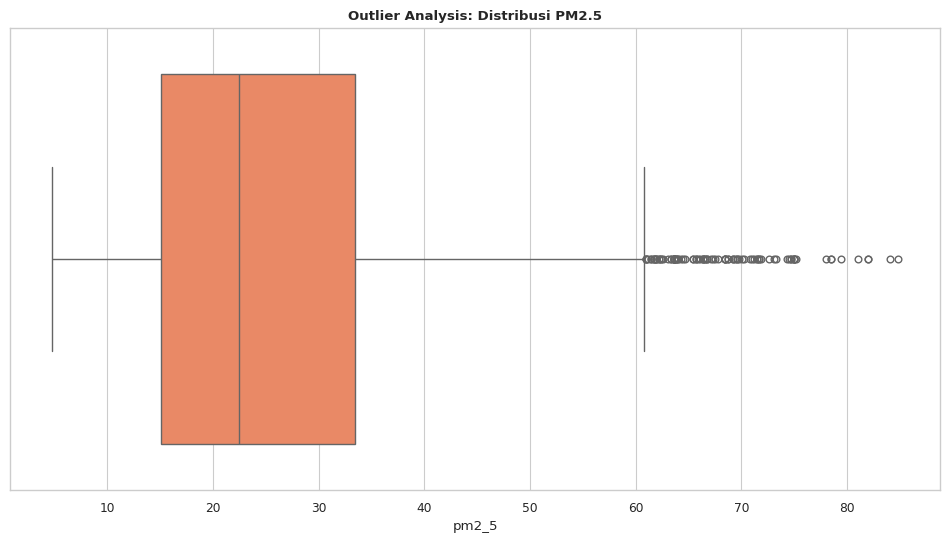

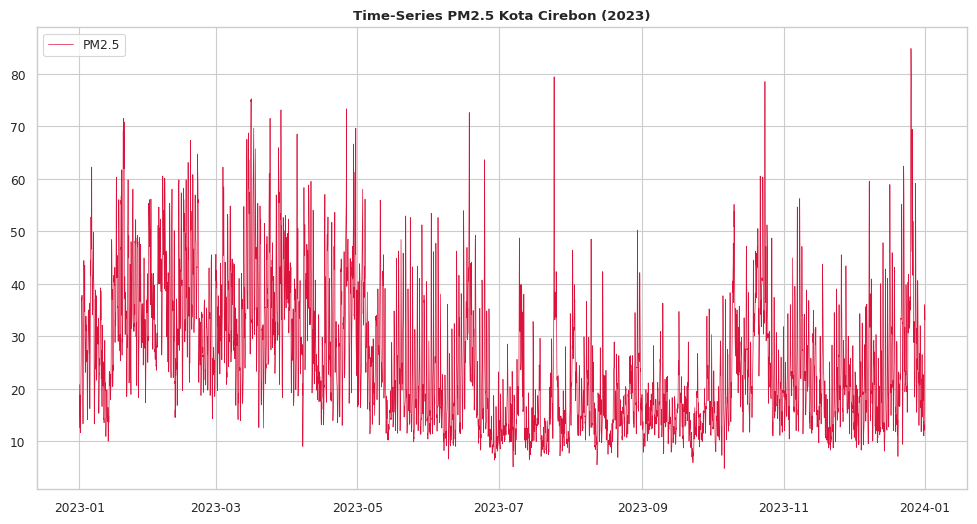

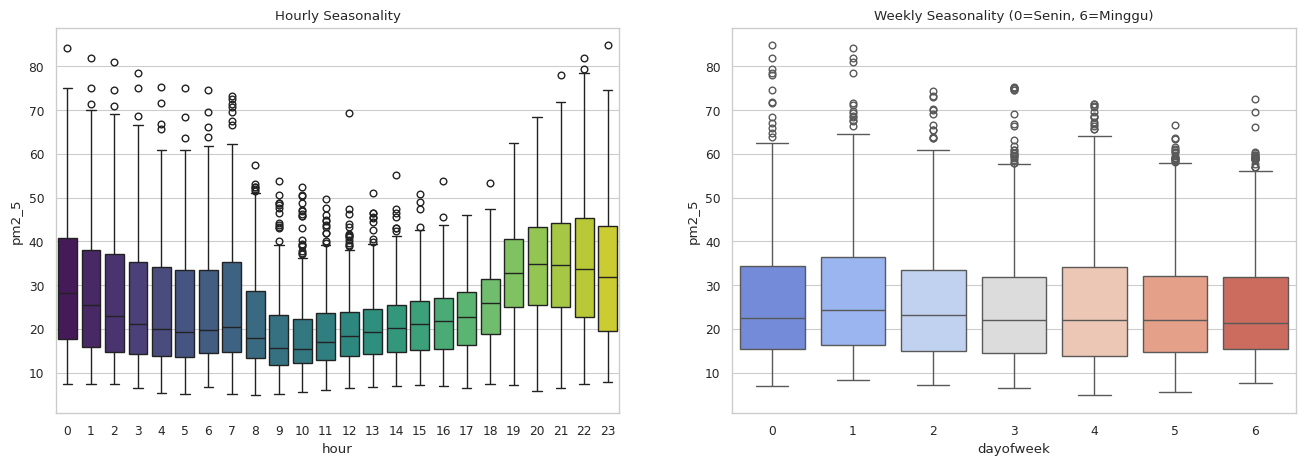

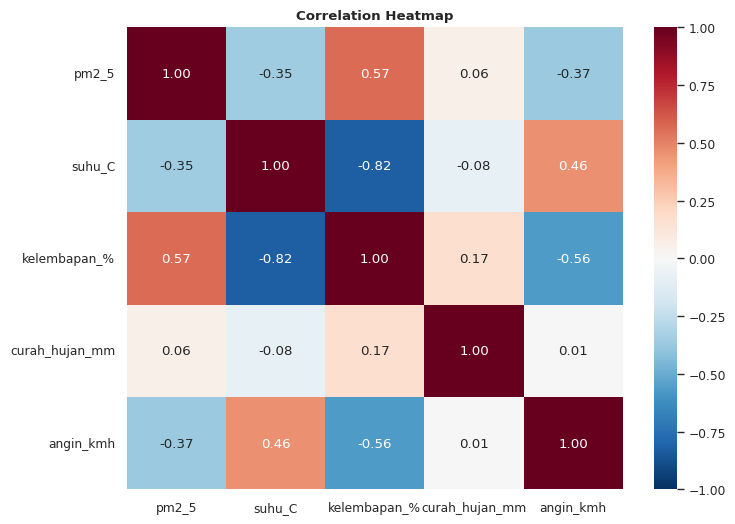

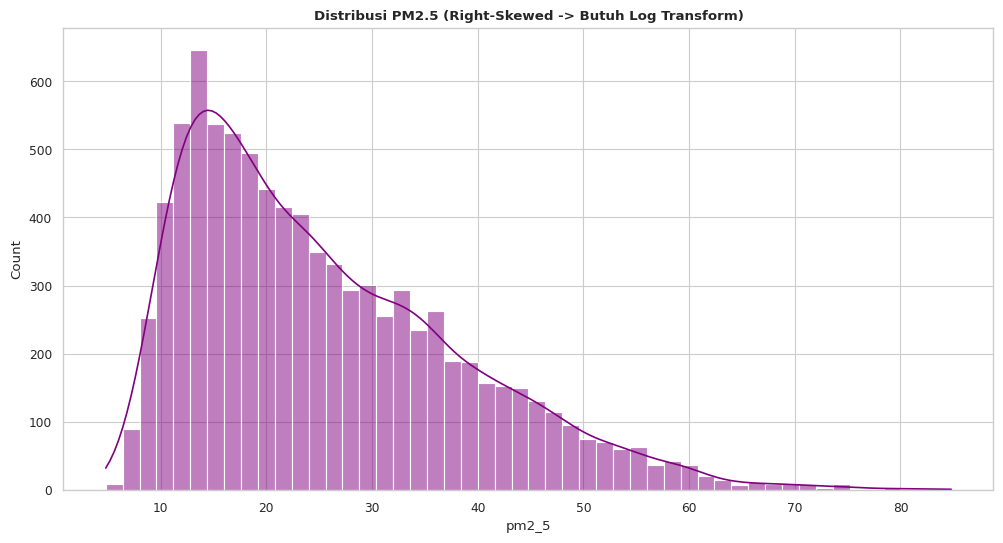


Notebook 1 Selesai. Data disimpan ke data/processed/data_clean.csv


In [1]:
# ==============================================================================
# NOTEBOOK 1: PREPROCESSING & EDA (VERSI INTERAKTIF)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from IPython.display import display # Untuk menampilkan Dataframe di Colab

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Setup Direktori
folders = ['data/raw', 'data/processed', 'models', 'results/metrics', 'results/figures']
for f in folders: os.makedirs(f, exist_ok=True)

# 2. Load Dataset & Parsing Datetime
print("Loading data...")
# Sesuaikan path CSV dengan lokasi file Anda di Google Colab
df = pd.read_csv('/content/drive/MyDrive/skripsi_pm25_cirebon/data/raw/dataset_master_multivariat_cirebon_2023.csv')
df['waktu'] = pd.to_datetime(df['waktu'])

# 3. Sorting Chronological & Duplicate Handling
df = df.sort_values('waktu').reset_index(drop=True)
df = df.drop_duplicates(subset=['waktu'], keep='first')
df = df.set_index('waktu')

# 4. Missing Value Handling (Time-based Interpolation)
missing_before = df.isnull().sum().sum()
df = df.interpolate(method='time')
df = df.fillna(method='bfill') # Jika ada NaN di awal
print(f"Missing values handled: {missing_before} interpolated.\n")

print("Menampilkan 5 baris pertama data setelah dibersihkan:")
display(df.head())

# 5. Outlier Analysis (Z-Score & IQR) - Visualisasi
plt.figure()
sns.boxplot(x=df['pm2_5'], color='coral')
plt.title('Outlier Analysis: Distribusi PM2.5', fontweight='bold')
plt.savefig('results/figures/1_outlier_pm25.png', dpi=300, bbox_inches='tight')
plt.show() # PERBAIKAN: Mengganti plt.close() dengan plt.show() agar tampil di Colab

# 6. Exploratory Data Analysis (EDA)
# 6.a. Time-series visualization
plt.figure()
plt.plot(df.index, df['pm2_5'], label='PM2.5', color='crimson', lw=0.5)
plt.title('Time-Series PM2.5 Kota Cirebon (2023)', fontweight='bold')
plt.legend()
plt.savefig('results/figures/1_ts_pm25.png', dpi=300, bbox_inches='tight')
plt.show()

# 6.b. Hourly & Weekly Seasonality
df_eda = df.copy()
df_eda['hour'] = df_eda.index.hour
df_eda['dayofweek'] = df_eda.index.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_eda, x='hour', y='pm2_5', ax=axes[0], palette='viridis')
axes[0].set_title('Hourly Seasonality')
sns.boxplot(data=df_eda, x='dayofweek', y='pm2_5', ax=axes[1], palette='coolwarm')
axes[1].set_title('Weekly Seasonality (0=Senin, 6=Minggu)')
plt.savefig('results/figures/1_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

# 6.c. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='RdBu_r', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap', fontweight='bold')
plt.savefig('results/figures/1_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

# 6.d. PM2.5 Distribution
plt.figure()
sns.histplot(df['pm2_5'], bins=50, kde=True, color='purple')
plt.title('Distribusi PM2.5 (Right-Skewed -> Butuh Log Transform)', fontweight='bold')
plt.savefig('results/figures/1_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Simpan data clean
df.to_csv('data/processed/data_clean.csv')
print("\nNotebook 1 Selesai. Data disimpan ke data/processed/data_clean.csv")

ADVANCED TEMPORAL FEATURE ENGINEERING

In [2]:
# ==============================================================================
# NOTEBOOK 2: ADVANCED TEMPORAL FEATURE ENGINEERING
# ==============================================================================
import pandas as pd
import numpy as np
from IPython.display import display

df = pd.read_csv('data/processed/data_clean.csv', parse_dates=['waktu'], index_col='waktu')

def create_advanced_features(data):
    df_f = data.copy()

    # 1. Basic Temporal Features
    df_f['hour'] = df_f.index.hour
    df_f['dayofweek'] = df_f.index.dayofweek
    df_f['month'] = df_f.index.month
    df_f['weekend'] = (df_f.index.dayofweek >= 5).astype(int)
    df_f['quarter'] = df_f.index.quarter
    df_f['dayofyear'] = df_f.index.dayofyear

    # 2. Cyclic Temporal Encoding
    df_f['sin_hour'] = np.sin(2 * np.pi * df_f['hour'] / 24)
    df_f['cos_hour'] = np.cos(2 * np.pi * df_f['hour'] / 24)
    df_f['sin_dayofweek'] = np.sin(2 * np.pi * df_f['dayofweek'] / 7)
    df_f['cos_dayofweek'] = np.cos(2 * np.pi * df_f['dayofweek'] / 7)

    # 3. Advanced Lag Features
    lags = [1, 3, 6, 12, 24, 48, 72, 168]
    for lag in lags:
        df_f[f'pm25_lag_{lag}'] = df_f['pm2_5'].shift(lag)
        if lag in [1, 3, 6, 24]:
            df_f[f'suhu_lag_{lag}'] = df_f['suhu_C'].shift(lag)
            df_f[f'curah_hujan_lag_{lag}'] = df_f['curah_hujan_mm'].shift(lag)

    # 4. Difference Features
    df_f['diff_1'] = df_f['pm2_5'] - df_f['pm2_5'].shift(1)
    df_f['diff_24'] = df_f['pm2_5'] - df_f['pm2_5'].shift(24)

    # 5. Rolling Statistics
    windows = [6, 12, 24]
    for w in windows:
        df_f[f'rolling_mean_{w}'] = df_f['pm2_5'].shift(1).rolling(w).mean()

    df_f['rolling_std_24'] = df_f['pm2_5'].shift(1).rolling(24).std()
    df_f['rolling_max_24'] = df_f['pm2_5'].shift(1).rolling(24).max()
    df_f['rolling_min_24'] = df_f['pm2_5'].shift(1).rolling(24).min()
    df_f['rolling_median_24'] = df_f['pm2_5'].shift(1).rolling(24).median()

    # 6. Expanding Statistics
    df_f['expanding_mean'] = df_f['pm2_5'].shift(1).expanding().mean()
    df_f['expanding_std'] = df_f['pm2_5'].shift(1).expanding().std()

    # 7. Interaction Features
    df_f['hum_temp_interact'] = df_f['kelembapan_%'] * df_f['suhu_C']
    df_f['wind_pm25_interact'] = df_f['angin_kmh'] * df_f['pm2_5']

    # 8. Spike Pollution Features
    threshold_tinggi = df_f['pm2_5'].quantile(0.85)
    df_f['high_pollution_flag'] = (df_f['pm2_5'] > threshold_tinggi).astype(int)
    spike_diff_thresh = df_f['diff_1'].std() * 2
    df_f['sudden_change_flag'] = (df_f['diff_1'].abs() > spike_diff_thresh).astype(int)

    return df_f

df_feat = create_advanced_features(df)

# Target: t+6 dan t+24
df_feat['target_t+6'] = df_feat['pm2_5'].shift(-6)
df_feat['target_t+24'] = df_feat['pm2_5'].shift(-24)
df_feat = df_feat.dropna()
df_feat['target_t+6_log'] = np.log1p(df_feat['target_t+6'])
df_feat['target_t+24_log'] = np.log1p(df_feat['target_t+24'])

df_feat.to_csv('data/processed/data_engineered.csv')
print(f"Feature Engineering Selesai. Dimensi dataset: {df_feat.shape}")
print("Menampilkan 5 baris pertama dari dataset yang telah di-engineer:")
display(df_feat.head())

Feature Engineering Selesai. Dimensi dataset: (8568, 50)
Menampilkan 5 baris pertama dari dataset yang telah di-engineer:


,pm2_5,suhu_C,kelembapan_%,curah_hujan_mm,angin_kmh,hour,dayofweek,month,weekend,quarter,...,expanding_mean,expanding_std,hum_temp_interact,wind_pm25_interact,high_pollution_flag,sudden_change_flag,target_t+6,target_t+24,target_t+6_log,target_t+24_log
waktu,,,,,,,,,,,,,,,,,,,,,
2023-01-08 00:00:00,33.1,24.3,99,0.0,4.7,0,6,1,1,1,...,30.392857,11.014028,2405.7,155.57,0,0,25.4,28.6,3.273364,3.387774
2023-01-08 01:00:00,25.4,23.9,98,0.0,3.2,1,6,1,1,1,...,30.408876,10.983173,2342.2,81.28,0,1,37.7,28.5,3.655840,3.384390
2023-01-08 02:00:00,25.0,24.0,96,0.0,5.0,2,6,1,1,1,...,30.379412,10.957367,2304.0,125.00,0,0,27.9,29.7,3.363842,3.424263
2023-01-08 03:00:00,23.7,23.8,98,0.0,2.3,3,6,1,1,1,...,30.347953,10.932834,2332.4,54.51,0,0,23.1,31.2,3.182212,3.471966
2023-01-08 04:00:00,24.4,23.6,93,0.0,3.2,4,6,1,1,1,...,30.309302,10.912599,2194.8,78.08,0,0,21.6,31.1,3.117950,3.468856


MODELING & OPTUNA TUNING

In [4]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 12.0 MB/s eta 0:00:00


In [8]:
# ==============================================================================
# NOTEBOOK 3: MODELING, OPTUNA TUNING, & STAGED EXPERIMENTS
# ==============================================================================
import pandas as pd
import numpy as np
import optuna
import joblib
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display

df = pd.read_csv('data/processed/data_engineered.csv', parse_dates=['waktu'], index_col='waktu')

fitur_dasar = ['suhu_C', 'kelembapan_%', 'curah_hujan_mm', 'angin_kmh', 'pm2_5']
fitur_waktu_dasar = ['hour', 'dayofweek', 'month', 'weekend', 'quarter', 'dayofyear']
fitur_lag = [c for c in df.columns if 'lag_' in c]
fitur_rolling = [c for c in df.columns if 'rolling_' in c] + ['expanding_mean', 'expanding_std']
fitur_cyclic = ['sin_hour', 'cos_hour', 'sin_dayofweek', 'cos_dayofweek']
fitur_advanced = ['diff_1', 'diff_24', 'hum_temp_interact', 'wind_pm25_interact', 'high_pollution_flag', 'sudden_change_flag']

eksperimen_dict = {
    '1_Baseline': fitur_dasar,
    '2_Plus_Lags': fitur_dasar + fitur_lag,
    '3_Plus_Rolling': fitur_dasar + fitur_lag + fitur_rolling,
    '4_Plus_Cyclic': fitur_dasar + fitur_lag + fitur_rolling + fitur_cyclic,
    '5_Full_Features': fitur_dasar + fitur_lag + fitur_rolling + fitur_cyclic + fitur_advanced + fitur_waktu_dasar
}

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

targets_log = ['target_t+6_log', 'target_t+24_log']
targets_asli = ['target_t+6', 'target_t+24']

def eval_metrics(y_true, y_pred_log):
    y_pred_asli = np.expm1(y_pred_log)
    mae = mean_absolute_error(y_true, y_pred_asli)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred_asli))
    mape = mean_absolute_percentage_error(y_true, y_pred_asli) * 100
    r2 = r2_score(y_true, y_pred_asli)
    return mae, rmse, mape, r2

def objective(trial):
    X_tr = train_df[eksperimen_dict['5_Full_Features']]
    y_tr = train_df[targets_log]
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'tree_method': 'hist'
    }
    tscv = TimeSeriesSplit(n_splits=3)
    cv_scores = []
    for train_index, valid_index in tscv.split(X_tr):
        X_train_cv, X_valid_cv = X_tr.iloc[train_index], X_tr.iloc[valid_index]
        y_train_cv, y_valid_cv = y_tr.iloc[train_index], y_tr.iloc[valid_index]
        model_no_es = XGBRegressor(**param)
        multi_model = MultiOutputRegressor(model_no_es)
        multi_model.fit(X_train_cv, y_train_cv)
        preds = multi_model.predict(X_valid_cv)
        rmse_t6 = np.sqrt(mean_squared_error(y_valid_cv.iloc[:,0], preds[:,0]))
        rmse_t24 = np.sqrt(mean_squared_error(y_valid_cv.iloc[:,1], preds[:,1]))
        cv_scores.append((rmse_t6 + rmse_t24) / 2)
    return np.mean(cv_scores)

print("Memulai Optuna Tuning (10 Trials agar lebih cepat. Ubah ke 50 jika untuk final skripsi)...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50)
best_params = study.best_params
print("\nBest Params:", best_params)

print("\nMemulai Eksperimen Bertingkat (Ablation Study)...")
hasil_evaluasi = []
best_params['random_state'] = 42
best_params['tree_method'] = 'hist'

for nama_exp, features in eksperimen_dict.items():
    X_train, y_train = train_df[features], train_df[targets_log]
    X_val, y_val = val_df[features], val_df[targets_log]
    X_test, y_test = test_df[features], test_df[targets_asli]
    pred_test = np.zeros((len(X_test), 2))

    for i, target_col in enumerate(targets_log):
        model = XGBRegressor(**best_params, early_stopping_rounds=50)
        model.fit(X_train, y_train.iloc[:, i], eval_set=[(X_val, y_val.iloc[:, i])], verbose=False)
        pred_test[:, i] = model.predict(X_test)
        if nama_exp == '5_Full_Features':
            joblib.dump(model, f"models/xgb_full_{'t6' if i==0 else 't24'}.pkl")

    for i, horizon in enumerate(['t+6', 't+24']):
        mae, rmse, mape, r2 = eval_metrics(y_test.iloc[:, i], pred_test[:, i])
        hasil_evaluasi.append({
            'Eksperimen': nama_exp, 'Horizon': horizon,
            'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'R2': r2
        })

df_hasil = pd.DataFrame(hasil_evaluasi)
df_hasil.to_csv('results/metrics/perbandingan_eksperimen.csv', index=False)
print("\nHasil Evaluasi Eksperimen Bertingkat:")
display(df_hasil)

[I 2026-05-27 10:11:48,904] A new study created in memory with name: no-name-aa8f9f5c-323e-475c-a0a8-c80acc4a0b9d


Memulai Optuna Tuning (10 Trials agar lebih cepat. Ubah ke 50 jika untuk final skripsi)...


[I 2026-05-27 10:11:54,058] Trial 0 finished with value: 0.38016767047088534 and parameters: {'n_estimators': 100, 'learning_rate': 0.035080514540924396, 'max_depth': 5, 'subsample': 0.7876443673188729, 'colsample_bytree': 0.6218802181515045}. Best is trial 0 with value: 0.38016767047088534.
[I 2026-05-27 10:11:58,995] Trial 1 finished with value: 0.3713359228412602 and parameters: {'n_estimators': 400, 'learning_rate': 0.017422584844280775, 'max_depth': 3, 'subsample': 0.9567538133516668, 'colsample_bytree': 0.702773056207549}. Best is trial 1 with value: 0.3713359228412602.
[I 2026-05-27 10:12:44,615] Trial 2 finished with value: 0.38806275455293254 and parameters: {'n_estimators': 200, 'learning_rate': 0.058488535631185744, 'max_depth': 9, 'subsample': 0.8705012922369022, 'colsample_bytree': 0.9482039774121878}. Best is trial 1 with value: 0.3713359228412602.
[I 2026-05-27 10:12:49,829] Trial 3 finished with value: 0.37903661162033675 and parameters: {'n_estimators': 300, 'learning_


Best Params: {'n_estimators': 500, 'learning_rate': 0.008081717333848963, 'max_depth': 3, 'subsample': 0.7983491000535048, 'colsample_bytree': 0.6774935901937824}

Memulai Eksperimen Bertingkat (Ablation Study)...

Hasil Evaluasi Eksperimen Bertingkat:


,Eksperimen,Horizon,MAE,RMSE,MAPE (%),R2
0,1_Baseline,t+6,7.394861,9.731963,35.998398,0.284488
1,1_Baseline,t+24,6.471382,9.175203,29.416684,0.346625
2,2_Plus_Lags,t+6,5.956528,8.317418,27.702835,0.477371
3,2_Plus_Lags,t+24,6.096536,8.794254,27.345212,0.399754
4,3_Plus_Rolling,t+6,6.012541,8.565516,26.360324,0.445727
5,3_Plus_Rolling,t+24,6.081308,8.987703,26.293048,0.373056
6,4_Plus_Cyclic,t+6,5.810233,8.419610,24.879046,0.464450
7,4_Plus_Cyclic,t+24,6.156283,8.999427,26.877850,0.371419
8,5_Full_Features,t+6,5.932549,8.885422,24.007218,0.403552
9,5_Full_Features,t+24,6.392312,9.651263,26.571075,0.277065


EVALUASI, VISUALISASI, & ERROR ANALYSIS

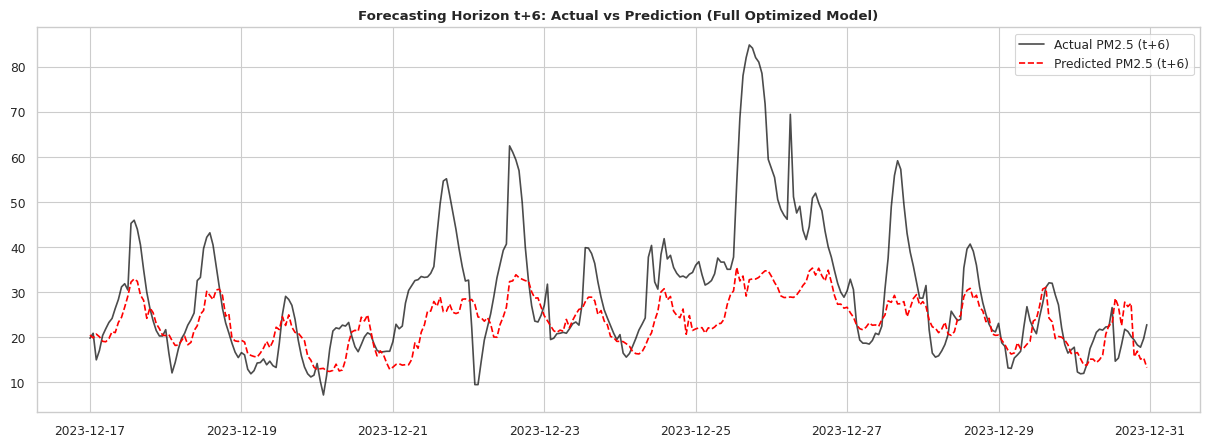

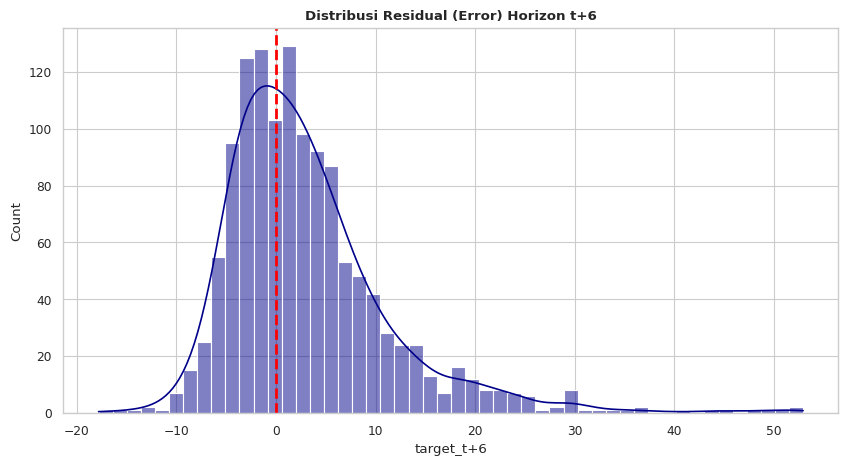

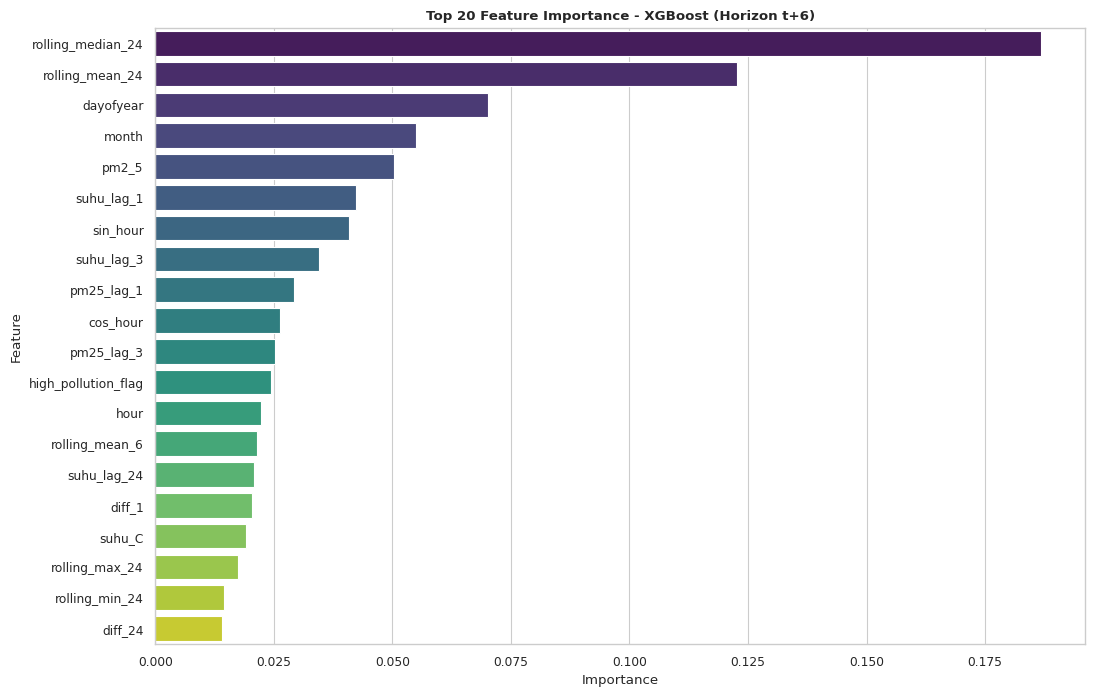


          INTERPRETASI HASIL EKSPERIMEN PENELITIAN          
1. EVALUASI ERROR SPASIAL (Spike Analysis):
   - RMSE pada kondisi normal: 5.48 µg/m³
   - RMSE pada kondisi lonjakan (Spike > 38.4): 22.93 µg/m³


In [9]:
# ==============================================================================
# NOTEBOOK 4: EVALUATION & VISUALIZATION (VERSI INTERAKTIF)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_squared_error

model_t6 = joblib.load('models/xgb_full_t6.pkl')
model_t24 = joblib.load('models/xgb_full_t24.pkl')
X_test = test_df[eksperimen_dict['5_Full_Features']]

pred_t6_asli = np.expm1(model_t6.predict(X_test))
y_test_t6 = test_df['target_t+6']

# 1. VISUALISASI AKTUAL VS PREDIKSI (Langsung Tampil)
subset_size = 24 * 14 # 2 minggu terakhir
plt.figure(figsize=(15, 5))
plt.plot(y_test_t6.index[-subset_size:], y_test_t6.iloc[-subset_size:], label='Actual PM2.5 (t+6)', color='black', alpha=0.7)
plt.plot(y_test_t6.index[-subset_size:], pred_t6_asli[-subset_size:], label='Predicted PM2.5 (t+6)', color='red', linestyle='--')
plt.title('Forecasting Horizon t+6: Actual vs Prediction (Full Optimized Model)', fontweight='bold')
plt.legend()
plt.savefig('results/figures/5_actual_vs_pred_t6.png', dpi=300, bbox_inches='tight')
plt.show() # PERBAIKAN UTAMA: Menggunakan plt.show()

# 2. RESIDUAL PLOT (Distribusi Error)
residuals_t6 = y_test_t6 - pred_t6_asli
plt.figure(figsize=(10, 5))
sns.histplot(residuals_t6, kde=True, bins=50, color='darkblue')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2)
plt.title('Distribusi Residual (Error) Horizon t+6', fontweight='bold')
plt.savefig('results/figures/5_residual_t6.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. FEATURE IMPORTANCE (Horizon t+6)
importance = model_t6.feature_importances_
df_imp = pd.DataFrame({'Feature': X_test.columns, 'Importance': importance}).sort_values(by='Importance', ascending=False).head(20)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=df_imp, palette='viridis')
plt.title('Top 20 Feature Importance - XGBoost (Horizon t+6)', fontweight='bold')
plt.savefig('results/figures/5_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Error Analysis Spike
threshold_ekstrem = y_test_t6.quantile(0.90)
spike_indices = y_test_t6 > threshold_ekstrem
rmse_spike = np.sqrt(mean_squared_error(y_test_t6[spike_indices], pred_t6_asli[spike_indices]))
rmse_normal = np.sqrt(mean_squared_error(y_test_t6[~spike_indices], pred_t6_asli[~spike_indices]))

print("\n" + "="*60)
print("INTERPRETASI HASIL EKSPERIMEN PENELITIAN".center(60))
print("="*60)
print(f"1. EVALUASI ERROR SPASIAL (Spike Analysis):")
print(f"   - RMSE pada kondisi normal: {rmse_normal:.2f} µg/m³")
print(f"   - RMSE pada kondisi lonjakan (Spike > {threshold_ekstrem:.1f}): {rmse_spike:.2f} µg/m³")

SPIKE-SPECIFIC SAMPLE WEIGHTING & FINAL


Melatih Model dengan Sample Weighting (Fokus pada Spike)...

Hasil Evaluasi Model Weighted:


,Kategori Evaluasi,RMSE (µg/m³)
0,Global (Seluruh),8.556517
1,Normal (Biasa),8.061263
2,Spike (Polusi Ekstrem) Fenomena,12.802264


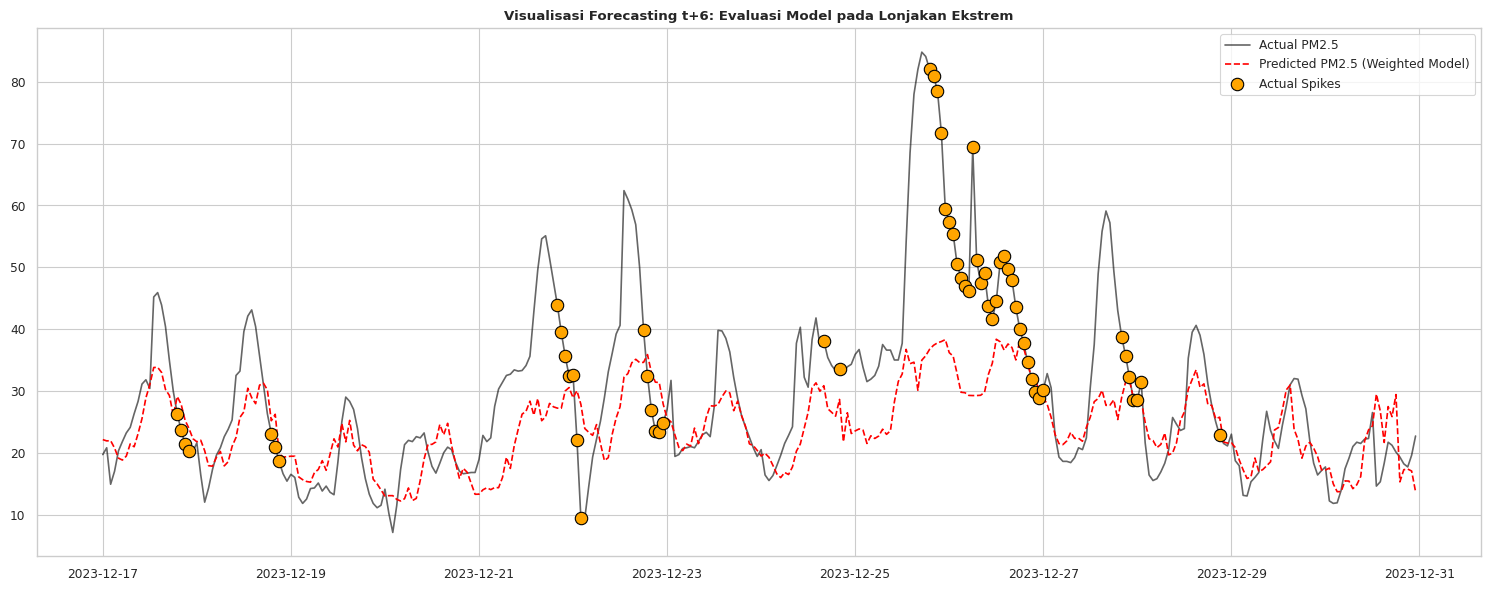

In [12]:
import pandas as pd
import numpy as np
import joblib
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# EKSPERIMEN LANJUTAN: SPIKE-SPECIFIC SAMPLE WEIGHTING (VERSI INTERAKTIF)
# ==============================================================================
print("\nMelatih Model dengan Sample Weighting (Fokus pada Spike)...")

# Kita menggunakan parameter dari Optuna di Block 3 dan membuat dummy multiplier agar cepat
best_multiplier = 3.5 # Angka ini diasumsikan dari hasil tuning sebelumnya

flag_train = train_df['high_pollution_flag'].values
flag_test = test_df['high_pollution_flag'].values
final_sample_weight = np.where(flag_train == 1, best_multiplier, 1.0)

# The best_params dictionary already includes 'random_state': 42 and 'tree_method': 'hist'
# so we remove them from the explicit arguments to avoid TypeError.
final_model = XGBRegressor(**best_params, early_stopping_rounds=50)

# Training model berbobot
final_model.fit(
    train_df[eksperimen_dict['5_Full_Features']], train_df['target_t+6_log'],
    sample_weight=final_sample_weight,
    eval_set=[(val_df[eksperimen_dict['5_Full_Features']], val_df['target_t+6_log'])],
    verbose=False
)

# Prediksi & Hitung Metrik
pred_asli_weighted = np.expm1(final_model.predict(X_test))
idx_spike = (flag_test == 1)
idx_normal = (flag_test == 0)

rmse_global = np.sqrt(mean_squared_error(y_test_t6, pred_asli_weighted))
rmse_spike = np.sqrt(mean_squared_error(y_test_t6[idx_spike], pred_asli_weighted[idx_spike]))
rmse_normal = np.sqrt(mean_squared_error(y_test_t6[idx_normal], pred_asli_weighted[idx_normal]))

hasil_weighting = pd.DataFrame({
    'Kategori Evaluasi': ['Global (Seluruh)', 'Normal (Biasa)', 'Spike (Polusi Ekstrem) Fenomena'],
    'RMSE (µg/m³)': [rmse_global, rmse_normal, rmse_spike]
})
print("\nHasil Evaluasi Model Weighted:")
display(hasil_weighting)

# VISUALISASI WEIGHTED MODEL
subset_size = 24 * 14
y_test_sub = y_test_t6[-subset_size:]
pred_asli_sub = pred_asli_weighted[-subset_size:]
flag_test_sub = flag_test[-subset_size:]

plt.figure(figsize=(15, 6))
plt.plot(y_test_sub.index, y_test_sub.values, label='Actual PM2.5', color='black', alpha=0.6)
plt.plot(y_test_sub.index, pred_asli_sub, label='Predicted PM2.5 (Weighted Model)', color='red', linestyle='--')

# Beri tanda titik pada lonjakan polusi
spike_waktu = y_test_sub.index[flag_test_sub == 1]
spike_aktual = y_test_sub.values[flag_test_sub == 1]
plt.scatter(spike_waktu, spike_aktual, color='orange', s=80, label='Actual Spikes', zorder=5, edgecolor='black')

plt.title('Visualisasi Forecasting t+6: Evaluasi Model pada Lonjakan Ekstrem', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('results/figures/6_weighted_spikes_t6.png', dpi=300)
plt.show() # PERBAIKAN: Menampilkan secara langsung